In [1]:
import numpy as np
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "mrpc"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import datasets
datasets.config.TORCHVISION_AVAILABLE = False

In [5]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [6]:
raw_datasets['train']

Dataset({
    features: ['sentence1', 'sentence2', 'label', 'idx'],
    num_rows: 3668
})

In [7]:
from datasets import DatasetDict

In [8]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation'],
    "test": raw_datasets['test']
})

In [9]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [10]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'sentence1': 'Amrozi accused his brother , whom he called " the witness " , of deliberately distorting his evidence .',
 'sentence2': 'Referring to him as only " the witness " , Amrozi accused his brother of deliberately distorting his evidence .',
 'label': 1,
 'idx': 0}

In [11]:
raw_train_dataset[5]['sentence1'], raw_train_dataset[5]['sentence2']

('Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .',
 "With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .")

In [12]:
raw_train_dataset[5]['label']

1

In [13]:
raw_train_dataset[5]['idx']

5

In [14]:
raw_train_dataset.features

{'sentence1': Value('string'),
 'sentence2': Value('string'),
 'label': ClassLabel(names=['not_equivalent', 'equivalent']),
 'idx': Value('int32')}

# 2. Preprocess

In [15]:
def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

# 3. Preparing for Training

In [16]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [17]:
tokenized_datasets = tokenized_datasets.remove_columns(["sentence1", "sentence2", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [18]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

eval_dataloader = DataLoader(
    tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
)

In [19]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 100]),
 'token_type_ids': torch.Size([32, 100]),
 'attention_mask': torch.Size([32, 100])}

In [20]:
run_layer = [
    {
        "times": 2,
        "run_heads": True,
        "run_wo": True,
        "run_ffn": True,
    }
    for _ in range(7)
]

run_layer

[{'times': 2, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 2, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 2, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 2, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 2, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 2, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 2, 'run_heads': True, 'run_wo': True, 'run_ffn': True}]

# 4. Load Model

In [21]:
import sys
sys.path.insert(0, '../')

In [22]:
from Bert_model.modeling_bert_para_sharing import BertForSequenceClassification

In [23]:
# id2label, label2id dicts for the outputs for the model
labels = tokenized_datasets["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

In [24]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [25]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [26]:
for i in range(11, 2, -2):
    del model.bert.encoder.layer[i]

In [27]:
model.bert.encoder.layer

ModuleList(
  (0-6): 7 x BertLayer(
    (attention): BertAttention(
      (self): BertSelfAttention(
        (query): Linear(in_features=768, out_features=768, bias=True)
        (key): Linear(in_features=768, out_features=768, bias=True)
        (value): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (output): BertSelfOutput(
        (dense): Linear(in_features=768, out_features=768, bias=True)
        (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
    (intermediate): BertIntermediate(
      (dense): Linear(in_features=768, out_features=3072, bias=True)
      (intermediate_act_fn): GELUActivation()
    )
    (output): BertOutput(
      (dense): Linear(in_features=3072, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False

In [28]:
outputs = model(**batch, run_layer=run_layer)
print(outputs.loss, outputs.logits.shape)

tensor(1.0981, grad_fn=<NllLossBackward0>) torch.Size([32, 2])


In [29]:
device = torch.device("cuda:1") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)

device

device(type='cuda', index=1)

In [30]:
from train_eval_func import eval_loop

In [31]:
eval_loop(model, eval_dataloader, task_name, device, run_layer=run_layer)

({'accuracy': 0.3344927536231884, 'f1': 0.0}, 0.9553504442727124)

# 5. Learning Rate and Leanring Scheduler Setup

In [32]:
from torch.optim import AdamW

optimizer = AdamW(model.parameters(), lr=3e-5)

In [33]:
from train_eval_func import set_lr_scheduler

num_epochs = 10
num_training_steps = num_epochs * len(train_dataloader)

lr_scheduler = set_lr_scheduler(
    optimizer          = optimizer,
    num_training_steps = num_training_steps
)

print(num_training_steps)

1150


In [34]:
patience=3
save_path=f'./weights/bert-{task_name}.pt'

# 6. Training

In [35]:
from train_eval_func import train

In [36]:
train_stats = train(
    model,
    train_dataloader,
    val_dataloader,
    task_name,
    device,
    num_epochs=num_epochs,
    lr=lr_scheduler,
    patience=patience,
    use_early_stopping=True,
    optimizer=optimizer,
    lr_scheduler=lr_scheduler,
    save_path=save_path,
    display_epoch_iter=True,
    run_layer=run_layer
)

Training:   0%|          | 0/1150 [00:00<?, ?it/s]/home/abhinavl/work/Layer_Graft/layer-grafting-publication/para_sharing_test/../train_eval_func.py:241: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  total_loss += float(loss)
Training:  10%|█         | 115/1150 [00:14<01:54,  9.01it/s]

✓ Saved checkpoint (best loss: 0.5147)

<----------------- Epoch 1 ----------------->
Loss: 0.59, Training Metrics:
  accuracy: 0.6927
  f1: 0.7996
Validation Loss: 0.51, Validation Metrics:
  accuracy: 0.7500
  f1: 0.8229
Elapsed Time: 15.7149 sec


Training:  20%|██        | 230/1150 [00:37<01:43,  8.93it/s]

✓ Saved checkpoint (best loss: 0.5207)

<----------------- Epoch 2 ----------------->
Loss: 0.47, Training Metrics:
  accuracy: 0.7865
  f1: 0.8474
Validation Loss: 0.52, Validation Metrics:
  accuracy: 0.7721
  f1: 0.8558
Elapsed Time: 15.2284 sec


Training:  30%|███       | 345/1150 [01:02<01:34,  8.55it/s]

✓ Saved checkpoint (best loss: 0.5153)

<----------------- Epoch 3 ----------------->
Loss: 0.29, Training Metrics:
  accuracy: 0.8770
  f1: 0.9097
Validation Loss: 0.52, Validation Metrics:
  accuracy: 0.7990
  f1: 0.8642
Elapsed Time: 15.9514 sec


... (2 outputs left out)

Training:  50%|█████     | 575/1150 [01:41<01:06,  8.64it/s]


<----------------- Epoch 5 ----------------->
Loss: 0.08, Training Metrics:
  accuracy: 0.9757
  f1: 0.9819
Validation Loss: 1.18, Validation Metrics:
  accuracy: 0.7721
  f1: 0.8507
Elapsed Time: 15.6488 sec


Training:  60%|██████    | 690/1150 [01:58<01:18,  5.83it/s]


<----------------- Epoch 6 ----------------->
Loss: 0.08, Training Metrics:
  accuracy: 0.9776
  f1: 0.9835
Validation Loss: 1.14, Validation Metrics:
  accuracy: 0.7843
  f1: 0.8533
Elapsed Time: 15.7734 sec
>>>>> Early stopping callback <<<<<

Total Training Time: 118.36 sec
Chosen Primary Metric: f1
Best Metric Run: 0.8642


### Plotting Loss

In [37]:
from train_eval_func import plotLoss, plotAccuracy

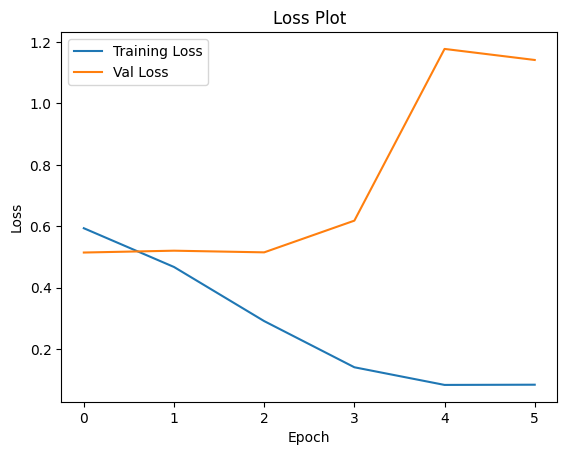

In [38]:
plotLoss(train_stats['train_losses'], train_stats['val_losses'], title="Loss Plot")

### Plotting Accuracy

In [39]:
def getMetricList(train_stats, metric_name='accuracy'):
    train_values = [m[metric_name] for m in train_stats['train_metrics_history']]
    val_values = [m[metric_name] for m in train_stats['val_metrics_history']]

    return train_values, val_values

In [40]:
train_values, val_values = getMetricList(train_stats)

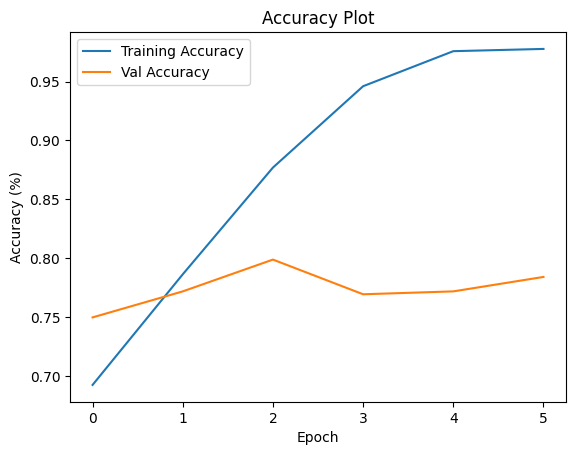

In [41]:
plotAccuracy(train_values, val_values, title="Accuracy Plot")

In [42]:
train_values, val_values = getMetricList(train_stats, 'f1')

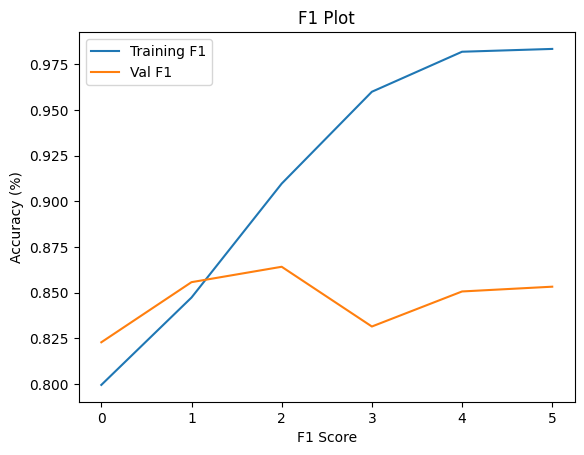

In [43]:
plotAccuracy(train_values, val_values, legend=["Training F1", "Val F1"], title="F1 Plot", xlabel="F1 Score")

# 7. Evaluation

In [44]:
best_weight = torch.load(save_path)

In [45]:
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [46]:
eval_loop(model, eval_dataloader, task_name, device, run_layer=run_layer)[0]

{'accuracy': 0.7617391304347826, 'f1': 0.8309337721102427}

In [47]:
eval_loop(model, val_dataloader, task_name, device, run_layer=run_layer)[0]

{'accuracy': 0.7990196078431373, 'f1': 0.8642384105960265}

In [48]:
best_weight['epoch']

3